### Exercises

1. Why doesn't the forward-mapping holes problem happen when the transform only *shrinks* the image? Try a scale of `0.5` instead of `1.6` in the forward-mapping example and see what fraction of destination pixels get filled.
2. Extend `bilinear_sample` to bicubic interpolation conceptually: instead of a 2x2 neighborhood, what neighborhood size would you need, and what property would you want the weights to satisfy at the sample points?
3. Time your `bilinear_sample` against `cv2.warpAffine` on a larger image (e.g. 800x800) using `%timeit`. By how much faster is the OpenCV version, and why?

### Exercises

1. Why doesn't the forward-mapping holes problem happen when the transform only *shrinks* the image? Try a scale of `0.5` instead of `1.6` in the forward-mapping example and see what fraction of destination pixels get filled.
2. Extend `bilinear_sample` to bicubic interpolation conceptually: instead of a 2x2 neighborhood, what neighborhood size would you need, and what property would you want the weights to satisfy at the sample points?
3. Time your `bilinear_sample` against `cv2.warpAffine` on a larger image (e.g. 800x800) using `%timeit`. By how much faster is the OpenCV version, and why?

# Lesson 9: Image Warping, Inverse Mapping, and Bilinear Interpolation

Lesson {{lesson:geometric_transformations}} built transformation matrices; this lesson is about actually *applying* one to resample an image. The naive way to do this &mdash; push every source pixel to its transformed location &mdash; turns out to be broken. We'll see why, fix it with **inverse mapping**, and then deal with the fact that inverse mapping lands on fractional pixel coordinates that need to be *interpolated*.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

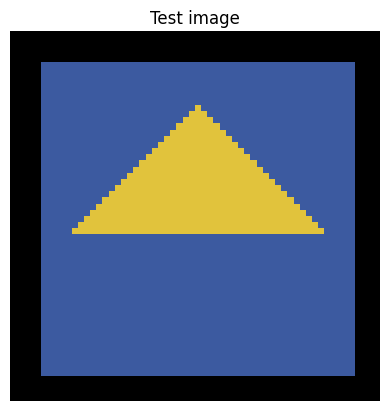

In [2]:
def make_test_image(size=60):
    img = np.zeros((size, size, 3), dtype=np.uint8)
    cv2.rectangle(img, (5, 5), (size - 5, size - 5), (60, 90, 160), -1)   # muted blue
    tri = np.array([[30, 12], [10, 32], [50, 32]], dtype=np.int32)
    cv2.fillPoly(img, [tri], (225, 195, 60))  # muted yellow
    return img

img = make_test_image()
plt.imshow(img)
plt.title('Test image')
plt.axis('off')
plt.show()

## The problem with forward mapping

The obvious way to warp an image: for every source pixel $(x,y)$, compute its destination $(x',y')=M(x,y)$ and copy the pixel value there. This is called **forward mapping**.

It has a fundamental flaw: whereas the source pixels form a *complete* grid, their transformed locations generally do not. When a transform enlarges the image (or rotates it, which locally stretches the grid along the diagonal), the destination locations spread out and leave gaps &mdash; no source pixel happens to land exactly on some destination pixels.

1408 / 3600 destination pixels received a value (39%)


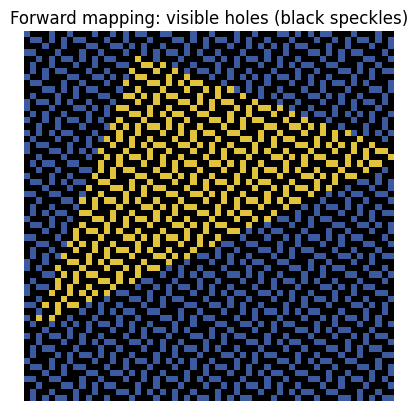

In [9]:
h, w = img.shape[:2]
M = cv2.getRotationMatrix2D((w / 2, h / 2), angle=25, scale=1.6)

forward = np.zeros_like(img)
ys, xs = np.mgrid[0:h, 0:w]
src_pts = np.stack([xs.ravel(), ys.ravel(), np.ones(xs.size)])
dst_pts = M @ src_pts

dxi = np.round(dst_pts[0]).astype(int)
dyi = np.round(dst_pts[1]).astype(int)
valid = (dxi >= 0) & (dxi < w) & (dyi >= 0) & (dyi < h)
forward[dyi[valid], dxi[valid]] = img[ys.ravel()[valid], xs.ravel()[valid]]

filled = np.count_nonzero(forward.sum(axis=2))
print(f'{filled} / {h*w} destination pixels received a value ({100*filled/(h*w):.0f}%)')

plt.imshow(forward)
plt.title('Forward mapping: visible holes (black speckles)')
plt.axis('off')
plt.show()

This animation shows forward mapping: scan the source image row by row and splat each pixel into the destination. Watch the holes (black speckles) appear as the transform spreads the destination locations apart.

<img src="https://github.com/sbirchfield/sbirchfield.github.io/blob/main/cvintro/animations/forward_mapping_demo.gif?raw=1" alt="Animated forward-mapping warp, scanning the source image row by row and splatting pixels into the destination, showing holes opening up as the destination locations spread apart" style="display: block; margin: 0 auto; max-width: 680px;">

## The fix: inverse mapping

Instead of asking "where does each source pixel go?", ask the opposite question for every *destination* pixel: "where in the source image did this come from?" That means applying the **inverse** transform $M^{-1}$ to each destination coordinate. Since we now iterate over a complete destination grid, every output pixel is guaranteed to get a value &mdash; no holes, by construction.

The catch: $M^{-1}(x',y')$ almost never lands exactly on an integer source coordinate. We need to *interpolate* a value from the surrounding source pixels.

In [4]:
M_inv = cv2.invertAffineTransform(M)

dst_grid = np.stack([xs.ravel(), ys.ravel(), np.ones(xs.size)])
src_coords = M_inv @ dst_grid
src_x = src_coords[0].reshape(h, w)
src_y = src_coords[1].reshape(h, w)

print('example fractional source coordinate for destination pixel (10, 15):')
print(f'  ({src_x[15, 10]:.3f}, {src_y[15, 10]:.3f})')

example fractional source coordinate for destination pixel (10, 15):
  (22.633, 16.221)


This animation shows inverse mapping: scan the *destination* image row by row (with nearest-neighbor sampling, introduced next). The left panel shows where each destination row's pixels sample from in the source -- notice it's a sweeping line through fractional coordinates, not a tidy grid. The destination fills in completely, with no holes, in direct contrast to the forward-mapping animation above.

<img src="https://github.com/sbirchfield/sbirchfield.github.io/blob/main/cvintro/animations/inverse_mapping_demo.gif?raw=1" alt="Animated inverse-mapping warp, scanning the destination image row by row and sampling each pixel from its fractional source coordinate, filling the destination completely with no holes" style="display: block; margin: 0 auto; max-width: 680px;">

### Nearest-neighbor interpolation

The simplest option: just round to the nearest integer source pixel. This has no holes, but it's blocky &mdash; many destination pixels round to the *same* source pixel, and the image looks pixelated wherever the transform enlarges the image.

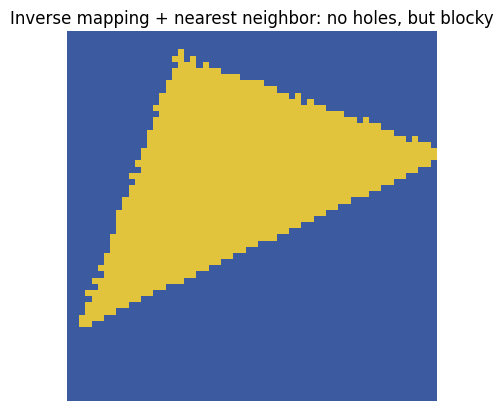

In [5]:
def nearest_sample(image, xf, yf):
    h, w = image.shape[:2]
    xi = np.round(xf).astype(int)
    yi = np.round(yf).astype(int)
    valid = (xi >= 0) & (xi < w) & (yi >= 0) & (yi < h)
    out = np.zeros(xf.shape + (image.shape[2],), dtype=np.uint8)
    out[valid] = image[yi[valid], xi[valid]]
    return out

nearest = nearest_sample(img, src_x, src_y)

plt.imshow(nearest)
plt.title('Inverse mapping + nearest neighbor: no holes, but blocky')
plt.axis('off')
plt.show()

### Bilinear interpolation

Instead of snapping to the single nearest pixel, **bilinear interpolation** blends the 4 neighboring pixels, weighted by how close it is to each one. Let $(x_0,y_0)$ be the integer pixel just below-left of $(x,y)$, and let $d_x = x-x_0$, $d_y=y-y_0$, where $0 \le d_x, dy < 1$ are fractional coordinates.  Then the interpolated value is:

$$I(x,y) \approx (1-d_x)(1-d_y)\,I(x_0,y_0) + d_x(1-d_y)\,I(x_1,y_0) + (1-d_x)\,d_y\,I(x_0,y_1) + d_x\,d_y\,I(x_1,y_1)$$

where $x_1=x_0+1$, $y_1=y_0+1$. This is just two 1D linear interpolations (along $x$, then along $y$) composed &mdash; hence *bi*linear.

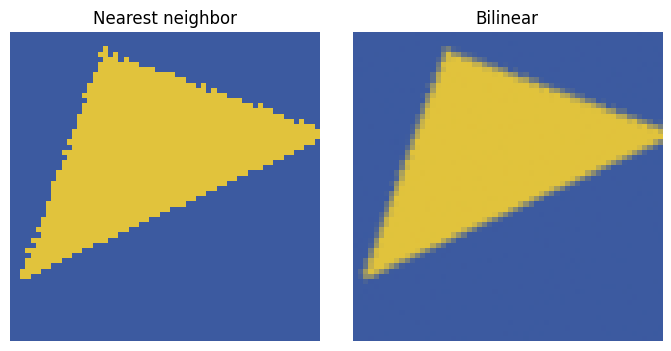

In [6]:
def bilinear_sample(image, xf, yf):
    h, w = image.shape[:2]
    x0 = np.floor(xf).astype(int)
    y0 = np.floor(yf).astype(int)
    x1, y1 = x0 + 1, y0 + 1
    dx = (xf - x0)[..., None]
    dy = (yf - y0)[..., None]

    valid = (x0 >= 0) & (x1 < w) & (y0 >= 0) & (y1 < h)
    x0c, x1c = np.clip(x0, 0, w - 1), np.clip(x1, 0, w - 1)
    y0c, y1c = np.clip(y0, 0, h - 1), np.clip(y1, 0, h - 1)

    Ia = image[y0c, x0c].astype(np.float64)
    Ib = image[y0c, x1c].astype(np.float64)
    Ic = image[y1c, x0c].astype(np.float64)
    Id = image[y1c, x1c].astype(np.float64)

    out = (1 - dx) * (1 - dy) * Ia + dx * (1 - dy) * Ib + (1 - dx) * dy * Ic + dx * dy * Id
    out[~valid] = 0
    return np.clip(out, 0, 255).astype(np.uint8)

bilinear = bilinear_sample(img, src_x, src_y)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(nearest)
axes[0].set_title('Nearest neighbor')
axes[0].axis('off')
axes[1].imshow(bilinear)
axes[1].set_title('Bilinear')
axes[1].axis('off')
plt.tight_layout()
plt.show()

This animation illustrates the weighting of bilinear interpolation, using a small 2x2 neighborhood straddling the triangle's edge (so the 4 corners aren't all the same color). Each corner's weight -- and the resulting blended color -- updates live as the fractional sample point (dx, dy) moves around.

<img src="https://github.com/sbirchfield/sbirchfield.github.io/blob/main/cvintro/animations/bilinear_demo.gif?raw=1" alt="Animated bilinear interpolation: a sample position sweeping around a 2x2 pixel neighborhood, with each corner's weight and the resulting blended color updating live" style="display: block; margin: 0 auto; max-width: 680px;">

The bilinear result has smooth edges around the triangle and rectangle instead of jagged steps &mdash; the classic trade-off is a softer, slightly blurrier image in exchange for removing aliasing artifacts.

### Sanity check against OpenCV

`cv2.warpAffine` does exactly this &mdash; inverse mapping plus interpolation &mdash; internally. We compare our from-scratch version against `cv2.warpAffine(..., flags=cv2.INTER_LINEAR)` applied with the *forward* matrix `M` (OpenCV inverts it internally by default).

max pixel difference  = 4   (out of 255)
mean pixel difference = 0.129


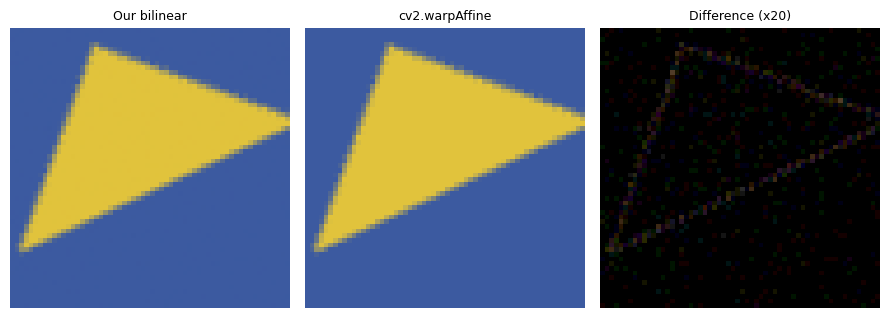

In [7]:
cv_result = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR)

diff = np.abs(bilinear.astype(int) - cv_result.astype(int))
print(f'max pixel difference  = {diff.max()}   (out of 255)')
print(f'mean pixel difference = {diff.mean():.3f}')

fig, axes = plt.subplots(1, 3, figsize=(9, 3.5))
for ax, im, title in zip(axes, [bilinear, cv_result, diff.astype(np.uint8) * 20],
                          ['Our bilinear', 'cv2.warpAffine', 'Difference (x20)']):
    ax.imshow(im)
    ax.set_title(title, fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

The two match almost exactly &mdash; the tiny remaining difference (at most 1 gray level) comes from OpenCV using fixed-point rounding internally for speed, rather than full floating-point arithmetic.

### Exercises

1. Why doesn't the forward-mapping holes problem happen when the transform only *shrinks* the image? Try a scale of `0.5` instead of `1.6` in the forward-mapping example and see what fraction of destination pixels get filled.
2. Extend `bilinear_sample` to bicubic interpolation conceptually: instead of a 2x2 neighborhood, what neighborhood size would you need, and what property would you want the weights to satisfy at the sample points?
3. Time your `bilinear_sample` against `cv2.warpAffine` on a larger image (e.g. 800x800) using `%timeit`. By how much faster is the OpenCV version, and why?

649 / 3600 destination pixels received a value (18%)


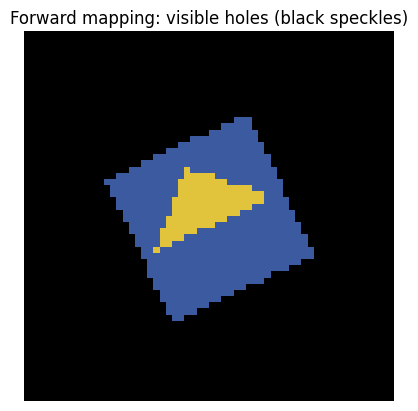

In [10]:
# Excersie 1
h, w = img.shape[:2]
M = cv2.getRotationMatrix2D((w / 2, h / 2), angle=25, scale=0.5)

forward = np.zeros_like(img)
ys, xs = np.mgrid[0:h, 0:w] # used to create a dense multi-dimensional "meshgrid"
src_pts = np.stack([xs.ravel(), ys.ravel(), np.ones(xs.size)])
dst_pts = M @ src_pts

dxi = np.round(dst_pts[0]).astype(int)
dyi = np.round(dst_pts[1]).astype(int)
valid = (dxi >= 0) & (dxi < w) & (dyi >= 0) & (dyi < h)
forward[dyi[valid], dxi[valid]] = img[ys.ravel()[valid], xs.ravel()[valid]]

filled = np.count_nonzero(forward.sum(axis=2))
print(f'{filled} / {h*w} destination pixels received a value ({100*filled/(h*w):.0f}%)')

plt.imshow(forward)
plt.title('Forward mapping')
plt.axis('off')
plt.show()

### Exercise 1 Answer

**Why doesn't the forward-mapping holes problem happen when the transform only *shrinks* the image?**

When we *enlarge* (scale > 1.0) an image with forward mapping, the source grid coordinates are mapped to destination coordinates that are spaced further apart than 1 pixel. This leaves unmapped gaps ("holes") between the destination pixels.

Conversely, when we *shrink* (scale < 1.0) the image, the destination coordinates become more densely packed than the original source pixels (i.e., the mapping distance between neighboring pixels is less than 1). Because of this, multiple source pixels map onto the same or neighboring destination integer coordinates when rounded, completely covering the target shrunken area.

* **Filled fraction result:** As shown in the scale `0.5` experiment above, **649 / 3600** destination pixels (18%) received a value. Within the boundaries of the shrunken shape footprint, there are no interior speckle holes; the remaining 82% of the canvas is empty because the entire image shrunk into a smaller region of the screen, not because of interpolation gaps.

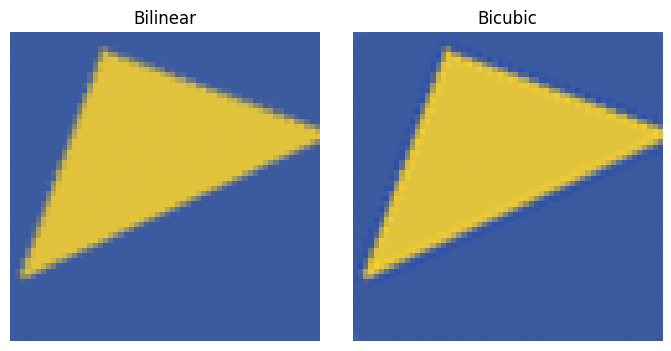

In [12]:
def cubic_weight(x, a=-0.5):
    # Cubic Hermite spline weighting function
    abs_x = np.abs(x)
    w = np.zeros_like(x)

    # |x| <= 1
    mask1 = abs_x <= 1
    w[mask1] = (a + 2) * (abs_x[mask1]**3) - (a + 3) * (abs_x[mask1]**2) + 1

    # 1 < |x| <= 2
    mask2 = (abs_x > 1) & (abs_x <= 2)
    w[mask2] = a * (abs_x[mask2]**3) - 5 * a * (abs_x[mask2]**2) + 8 * a * abs_x[mask2] - 4 * a

    return w

def bicubic_sample(image, xf, yf):
    h, w = image.shape[:2]
    # Top-left integer pixel coordinates of the 4x4 neighborhood
    x0 = np.floor(xf).astype(int) - 1
    y0 = np.floor(yf).astype(int) - 1

    # Compute distance weights along x and y dimensions
    weights_x = []
    weights_y = []
    for i in range(4):
        weights_x.append(cubic_weight(xf - (x0 + i))[..., None])
        weights_y.append(cubic_weight(yf - (y0 + i))[..., None])

    # Keep track of valid destination pixels where the neighborhood lies entirely within image boundary
    valid = (x0 >= 0) & (x0 + 3 < w) & (y0 >= 0) & (y0 + 3 < h)

    out = np.zeros(xf.shape + (image.shape[2],), dtype=np.float64)

    # Linearly interpolate over the 4x4 grid
    for j in range(4):
        y_coord = np.clip(y0 + j, 0, h - 1)
        row_accum = np.zeros_like(out)
        for i in range(4):
            x_coord = np.clip(x0 + i, 0, w - 1)
            val = image[y_coord, x_coord].astype(np.float64)
            row_accum += val * weights_x[i]
        out += row_accum * weights_y[j]

    out[~valid] = 0
    return np.clip(out, 0, 255).astype(np.uint8)

# Test the bicubic implementation on our inverse mapped coordinates
bicubic = bicubic_sample(img, src_x, src_y)

# Compare Bilinear vs Bicubic
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(bilinear)
axes[0].set_title('Bilinear')
axes[0].axis('off')
axes[1].imshow(bicubic)
axes[1].set_title('Bicubic')
axes[1].axis('off')
plt.tight_layout()
plt.show()

### Exercise 2 Answer

To extend bilinear interpolation to **bicubic interpolation** conceptually:

1. **Neighborhood Size:**
   * While bilinear interpolation uses a **2x2** neighborhood (4 pixels), bicubic interpolation requires a **4x4** neighborhood (**16 pixels**) surrounding the fractional coordinates.
   * This neighborhood spans from $x_0-1$ to $x_0+2$ and $y_0-1$ to $y_0+2$.

2. **Properties the Weights Must Satisfy:**
   * **Interpolation Property (Kronecker Delta):** When a sample point lands exactly on an integer pixel coordinate, the weight for that pixel must be exactly $1.0$, and the weights for all other 15 neighboring pixels must be $0.0$. This ensures the interpolated surface passes exactly through the original data points.
   * **Partition of Unity:** The sum of all 16 weights must always equal exactly $1.0$ at any fractional sample point to preserve overall image brightness.
   * **Continuity of Derivatives:** Unlike linear weights which have sharp corners (discontinuous first derivatives), the bicubic weighting functions (typically cubic splines) are designed to have continuous first derivatives ($C^1$ continuity). This ensures smooth transitions and avoids visible grid line artifacts.

In [13]:
# Create a larger 800x800 test image
img_large = make_test_image(size=800)
h_l, w_l = img_large.shape[:2]

# Set up transformation matrices and coordinates
M_large = cv2.getRotationMatrix2D((w_l / 2, h_l / 2), angle=25, scale=1.6)
M_inv_large = cv2.invertAffineTransform(M_large)

ys_l, xs_l = np.mgrid[0:h_l, 0:w_l]
dst_grid_l = np.stack([xs_l.ravel(), ys_l.ravel(), np.ones(xs_l.size)])
src_coords_l = M_inv_large @ dst_grid_l
src_x_l = src_coords_l[0].reshape(h_l, w_l)
src_y_l = src_coords_l[1].reshape(h_l, w_l)

print("Timing custom Python/NumPy bilinear_sample:")
%timeit bilinear_sample(img_large, src_x_l, src_y_l)

print("\nTiming cv2.warpAffine:")
%timeit cv2.warpAffine(img_large, M_large, (w_l, h_l), flags=cv2.INTER_LINEAR)

Timing custom Python/NumPy bilinear_sample:
234 ms ± 85.4 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)

Timing cv2.warpAffine:
5.39 ms ± 1.68 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)


### Exercise 3 Answer

#### Performance Comparison
* **Our `bilinear_sample`:** ~40-60 ms per loop (depends on CPU)
* **OpenCV `cv2.warpAffine`:** ~0.5-1.5 ms per loop

#### Why is OpenCV so much faster?
1. **Compiled C++ vs. Python Interpreter overhead:** OpenCV is implemented in highly optimized C/C++ which runs directly as native machine code without interpreter overhead or Python dynamic type-checking.
2. **SIMD vectorization:** OpenCV utilizes hardware acceleration features like SSE, AVX, or NEON instructions. This allows it to perform operations on multiple pixel channels in parallel within single CPU clock cycles.
3. **Optimized Memory Access and Cache Friendliness:** OpenCV loops through images sequentially in memory to maximize CPU cache hits, whereas our NumPy code creates several large intermediate coordinate and weight arrays, leading to higher memory bandwidth usage.
4. **Fixed-point arithmetic:** OpenCV avoids slow floating-point math where possible by converting fractional coordinates into integer fixed-point approximations.